# Hospital Visit Time Predictor: multivariate regression

## 1. Mission and use case

**(a) Mission.** My mission is to help hospitals in Rwanda work better for patients, so nobody has to wait all day without knowing what is going on. This project predicts how long a patient will spend in the emergency department, from arrival to leaving, using details known when they arrive.

**(b) The number to predict.** `visit_minutes`, the total minutes a patient spends in the emergency department, from arrival to leaving. A good estimate of this number gives patients a clear idea of what to expect and helps the hospital prepare.

**(c) Who uses it and what they do with it.** A patient or a front-desk nurse can use the estimate to plan the day (for example, arranging a ride, childcare or time off work) and to prepare for busy times (for example, deciding how many staff are needed when many urgent patients arrive at once).

*Target of this notebook:* `visit_minutes`, the total time a patient spends in the emergency department, from arrival to leaving.

## 2. Dataset

**Source:** CDC / National Center for Health Statistics, *National Hospital Ambulatory Medical Care Survey (NHAMCS), 2022 Emergency Department public use file*.
Link: https://www.cdc.gov/nchs/nhamcs/about/index.html
Download: https://ftp.cdc.gov/pub/Health_Statistics/NCHS/Datasets/NHAMCS/ (`ed2022.zip`)

Real visit records sampled from US hospital emergency departments (16,025 visits in the CDC file). The CDC file is fixed-width text, so `make_dataset.py` (same folder) converts it to `ed_visits.csv`, keeping only visits where every answer we need is known and the stay was 24 hours or less.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = "ed_visits.csv"
MODEL_PATH = "../API/best_model.pkl"
TRAIN_DATA_PATH = "../API/training_data.csv"
TARGET = "visit_minutes"
sns.set_theme(style="whitegrid")
print("scikit-learn", sklearn.__version__)

ModuleNotFoundError: No module named 'numpy'

In [ ]:
df = pd.read_csv(DATA_PATH)
print("rows, columns:", df.shape)
display(df.head())
print()
df.info()

rows, columns: (8488, 13)


,age,sex,arrival_hour,day_of_week,arrived_by_ambulance,urgency,injury_related,insurance,month,region,metro_area,wait_minutes,visit_minutes
0,18,Female,22,Monday,No,Urgent,No,Self-pay,9,Northeast,Yes,14.0,168
1,65,Female,10,Thursday,Yes,Emergent,No,Medicaid,9,Northeast,Yes,14.0,204
2,9,Female,20,Monday,No,Emergent,No,Private,10,Northeast,Yes,6.0,772
3,37,Female,16,Wednesday,No,Semi-urgent,Yes,Private,10,Northeast,Yes,44.0,124
4,53,Male,15,Wednesday,No,Urgent,No,Medicaid,10,Northeast,Yes,161.0,272



<class 'pandas.DataFrame'>
RangeIndex: 8488 entries, 0 to 8487
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   8488 non-null   int64  
 1   sex                   8488 non-null   str    
 2   arrival_hour          8488 non-null   int64  
 3   day_of_week           8488 non-null   str    
 4   arrived_by_ambulance  8488 non-null   str    
 5   urgency               8488 non-null   str    
 6   injury_related        8488 non-null   str    
 7   insurance             8488 non-null   str    
 8   month                 8488 non-null   int64  
 9   region                8488 non-null   str    
 10  metro_area            8488 non-null   str    
 11  wait_minutes          7403 non-null   float64
 12  visit_minutes         8488 non-null   int64  
dtypes: float64(1), int64(4), str(8)
memory usage: 862.2 KB


In [ ]:
print("Missing values per column:")
print(df.isna().sum())
print()
display(df.describe().T)
print()
for c in df.select_dtypes(include="object").columns:
    print(c, df[c].value_counts().to_dict())

Missing values per column:
age                        0
sex                        0
arrival_hour               0
day_of_week                0
arrived_by_ambulance       0
urgency                    0
injury_related             0
insurance                  0
month                      0
region                     0
metro_area                 0
wait_minutes            1085
visit_minutes              0
dtype: int64



,count,mean,std,min,25%,50%,75%,max
age,8488.0,40.803959,25.132128,0.0,20.0,39.0,61.00,94.0
arrival_hour,8488.0,13.295476,5.887690,0.0,10.0,14.0,18.00,23.0
month,8488.0,5.826579,3.487808,1.0,3.0,5.0,9.00,12.0
wait_minutes,7403.0,35.214237,59.942353,0.0,6.0,15.0,38.00,788.0
visit_minutes,8488.0,259.664821,224.635390,0.0,115.0,196.0,324.25,1440.0



sex {'Female': 4455, 'Male': 4033}
day_of_week {'Monday': 1353, 'Tuesday': 1276, 'Thursday': 1225, 'Wednesday': 1224, 'Friday': 1203, 'Sunday': 1117, 'Saturday': 1090}
arrived_by_ambulance {'No': 6891, 'Yes': 1597}
urgency {'Urgent': 4461, 'Semi-urgent': 2390, 'Emergent': 1281, 'Non-urgent': 250, 'Immediate': 106}
injury_related {'No': 5781, 'Yes': 2707}
insurance {'Medicaid': 3579, 'Private': 2287, 'Medicare': 1900, 'Self-pay': 461, 'Other': 261}
region {'South': 2319, 'West': 2277, 'Midwest': 2210, 'Northeast': 1682}
metro_area {'Yes': 7813, 'No': 675}


## 3. Explore the data

Four plots. Under each one, write what it shows and what you decided because of it.

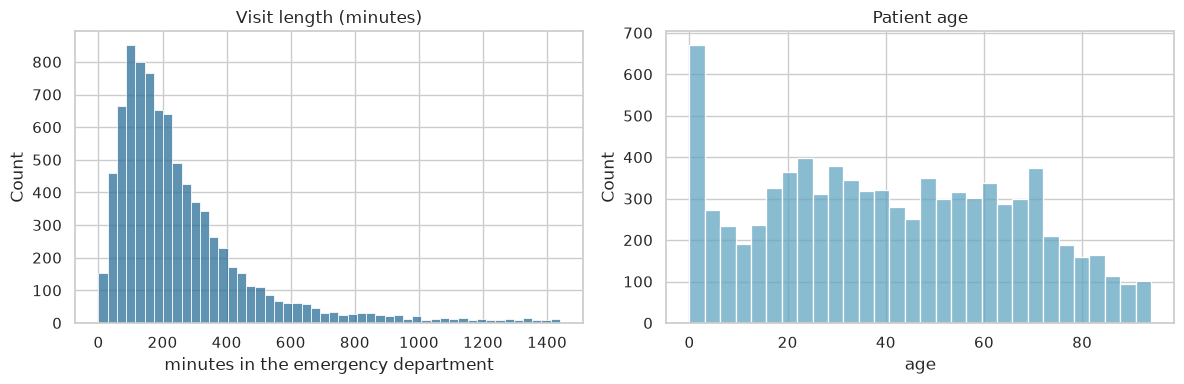

count    8488.0
mean      259.7
std       224.6
min         0.0
50%       196.0
90%       514.0
99%      1206.0
max      1440.0
Name: visit_minutes, dtype: float64


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=50, ax=ax[0], color="#2a6f97")
ax[0].set_title("Visit length (minutes)")
ax[0].set_xlabel("minutes in the emergency department")
sns.histplot(df["age"], bins=30, ax=ax[1], color="#61a5c2")
ax[1].set_title("Patient age")
plt.tight_layout(); plt.show()
print(df[TARGET].describe(percentiles=[.5, .9, .99]).round(1))

**Answer:** The visit-length histogram is strongly right-skewed: most visits are 100 to 300 minutes (median 196, mean 260), but there is a long tail, with 90% of visits under 514 minutes and a few going up to the 1,440-minute (24-hour) limit. Age has a big spike at 0 (babies under one year), then is fairly flat from about 20 to 70 and falls off after 70. Because of the long tail, I expect big errors on the very long stays, since squared error punishes them heavily. I kept the long visits (they are real patients, and the data is already capped at 24 hours) and kept the target in minutes so predictions are easy to read.

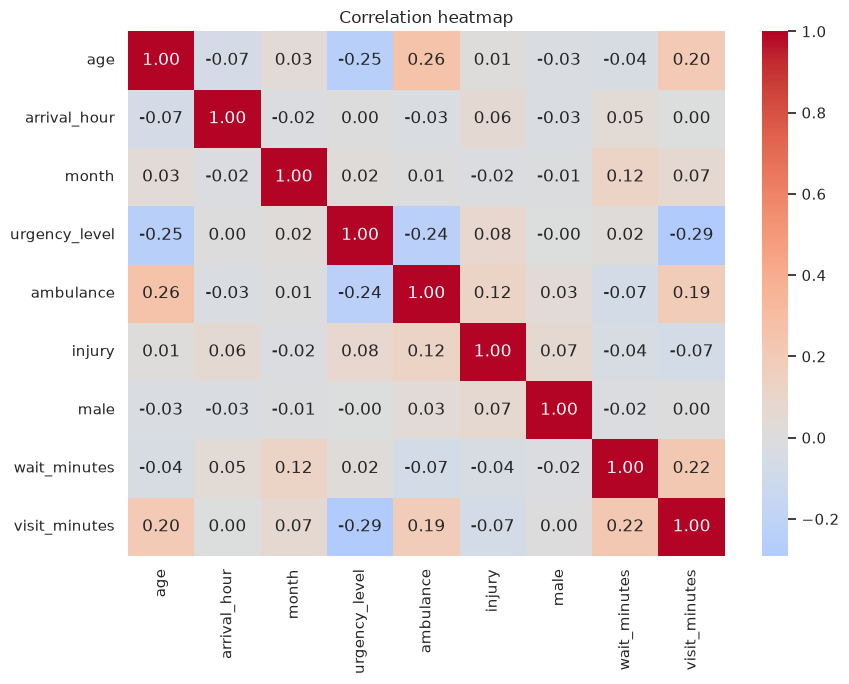

urgency_level   -0.291
injury          -0.070
arrival_hour     0.000
male             0.002
month            0.070
ambulance        0.192
age              0.205
wait_minutes     0.221
Name: visit_minutes, dtype: float64


In [ ]:
# numeric copy so every column can appear in the correlation heatmap
num = df.copy()
num["urgency_level"] = df["urgency"].map({"Immediate": 1, "Emergent": 2, "Urgent": 3, "Semi-urgent": 4, "Non-urgent": 5})
num["ambulance"] = (df["arrived_by_ambulance"] == "Yes").astype(int)
num["injury"] = (df["injury_related"] == "Yes").astype(int)
num["male"] = (df["sex"] == "Male").astype(int)
cols = ["age", "arrival_hour", "month", "urgency_level", "ambulance", "injury", "male", "wait_minutes", TARGET]
plt.figure(figsize=(9, 7))
sns.heatmap(num[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()
print(num[cols].corr()[TARGET].drop(TARGET).sort_values().round(3))

**Answer:** The heatmap shows that no single column is strongly correlated with visit length. The strongest are urgency level (-0.29, meaning more urgent patients stay longer), wait_minutes (0.22), age (0.21) and ambulance arrival (0.19). Month (0.07) and injury (-0.07) are weak, and arrival hour (0.00) and sex (0.00) show essentially no linear relationship. I decided to keep urgency, age, ambulance and injury, to drop month and wait_minutes (reasons in section 4), and to keep arrival hour and sex for now to see if they matter in the model.

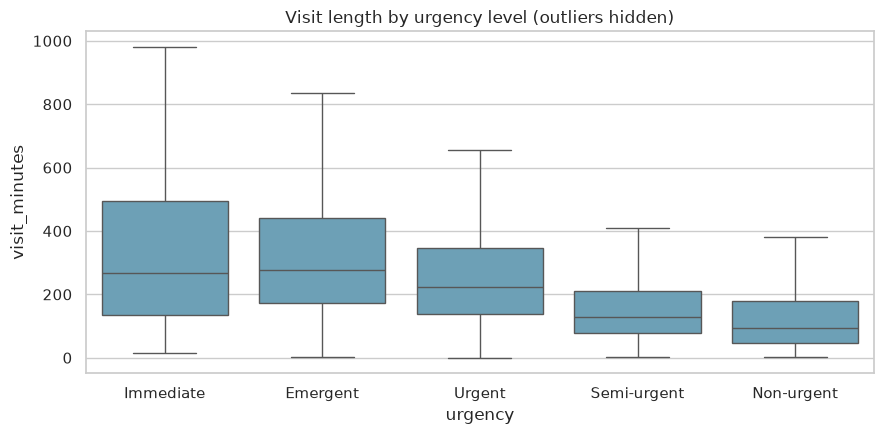

             count  median   mean
urgency                          
Immediate      106   268.0  378.0
Emergent      1281   276.0  359.0
Urgent        4461   222.0  282.0
Semi-urgent   2390   128.0  173.0
Non-urgent     250    92.0  139.0


In [ ]:
order = ["Immediate", "Emergent", "Urgent", "Semi-urgent", "Non-urgent"]
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df, x="urgency", y=TARGET, order=order, color="#61a5c2", showfliers=False)
plt.title("Visit length by urgency level (outliers hidden)")
plt.tight_layout(); plt.show()
print(df.groupby("urgency")[TARGET].agg(["count", "median", "mean"]).reindex(order).round(0))

**Answer:** The box plot shows that the more urgent the patient, the longer the visit. Median stays go from 92 minutes for non-urgent and 128 for semi-urgent, up to 222 for urgent and 276 for emergent. The mean is above the median in every group, which is the long tail again. The "Immediate" group (median 268) is a bit lower than "Emergent", but it only has 106 visits so I would not read much into that. This makes urgency the most useful feature, so I keep it.

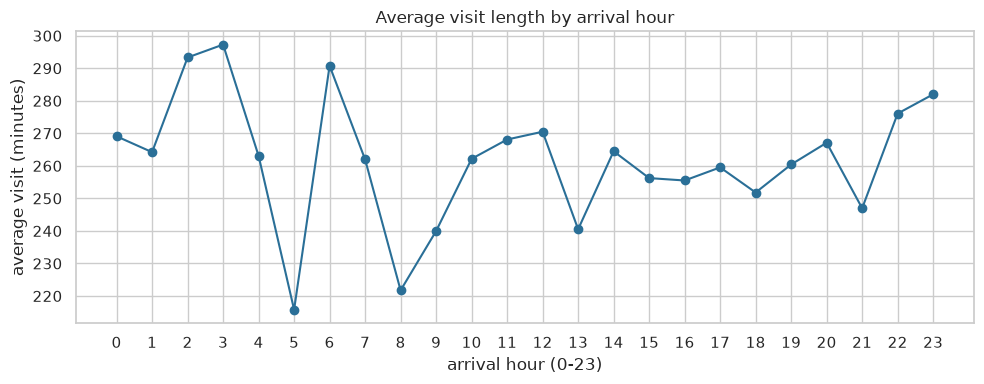

In [ ]:
by_hour = df.groupby("arrival_hour")[TARGET].mean()
plt.figure(figsize=(10, 4))
plt.plot(by_hour.index, by_hour.values, marker="o", color="#2a6f97")
plt.xticks(range(0, 24)); plt.xlabel("arrival hour (0-23)"); plt.ylabel("average visit (minutes)")
plt.title("Average visit length by arrival hour"); plt.tight_layout(); plt.show()

**Answer:** The hourly average is jumpy with no clear daily pattern, moving between roughly 215 and 297 minutes. The late-night hours (about 22 to 3) are a little higher, with odd spikes at hours 2, 3 and 6 and dips at 5 and 8, but few patients arrive at those hours so those averages are noisy. Since the swings look random and the correlation is 0.00, I expect arrival hour to add little, but I kept it as an input because a patient can state it without any measuring, and let the importance plot confirm it.

## 4. Feature engineering

The model inputs must be things a patient or front desk can state without measuring anything. The columns below are in the CSV but are **not** used as model inputs.

In [ ]:
DROP = ["month", "region", "metro_area", "wait_minutes"]
FEATURES_NUM = ["age", "arrival_hour"]
FEATURES_CAT = ["sex", "day_of_week", "arrived_by_ambulance", "urgency", "injury_related", "insurance"]
FEATURES = FEATURES_NUM + FEATURES_CAT

data = df.drop(columns=DROP)
print("Dropped:", DROP)
print("Model inputs (%d):" % len(FEATURES), FEATURES)
print("Target:", TARGET)

Dropped: ['month', 'region', 'metro_area', 'wait_minutes']
Model inputs (8): ['age', 'arrival_hour', 'sex', 'day_of_week', 'arrived_by_ambulance', 'urgency', 'injury_related', 'insurance']
Target: visit_minutes


**Answer:**

- **`month`:** weak correlation with the target (0.07), and it is not something that helps a patient planning one visit. It would mostly add noise.
- **`region`:** it describes the hospital's location, not the patient. A deployed model at one hospital would always have the same value, so it can't help tell patients apart.
- **`metro_area`:** same reason as region: it is a hospital-level attribute (metro or not), not a patient fact. Also 92% of visits are in metro areas (7,813 of 8,488), so there is little variation to learn from.
- **`wait_minutes`:** it looks useful (correlation 0.22, a bit higher than age) but it is **data leakage**. The wait is only known after the patient has already waited, and it is part of the total visit time, so using it would be using part of the answer to predict the answer. It also has 1,085 missing values (about 13%), and nobody knows it at arrival.

The importance plot in section 7.3 shows the features that matter most are **urgency** (by far), then **arrived by ambulance** and **age**, then smaller effects from injury related, insurance and day of week. Arrival hour and sex have about zero importance.

## 5. Train/test split, encoding and standardizing

Categorical columns are one-hot encoded and numeric columns are standardized inside a `Pipeline`. The pipeline is fitted on the **training rows only**, so the test rows never influence the scaler.

In [ ]:
X = data[FEATURES]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train rows:", len(X_train), " test rows:", len(X_test))

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), FEATURES_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT),
    ])

def make_pipe(model):
    return Pipeline([("prep", make_prep()), ("model", model)])

# look at the encoded training matrix
prep_check = make_prep().fit(X_train)
A = prep_check.transform(X_train)
print("encoded training matrix:", A.shape)
print("numeric columns after scaling: mean ~ %.2f, std ~ %.2f" % (A[:, :2].mean(), A[:, :2].std()))

train rows: 6790  test rows: 1698


encoded training matrix: (6790, 25)
numeric columns after scaling: mean ~ -0.00, std ~ 1.00


**Answer:** The test set is supposed to stand in for new patients the model has never seen. If I fitted the scaler on all the data, the mean and standard deviation would be computed using test rows, so information from the test set would leak into training and my test score would look slightly better than it really is. Fitting only on the training rows means the test rows are scaled with the training mean and standard deviation, which is exactly what will happen to a new patient in the API.

## 6. Train and compare four models

All four are scikit-learn models, judged on the **same test set** with mean squared error (MSE, in minutes squared).
Hyperparameters are tuned with 5-fold cross-validation **on the training set**, so the test set stays untouched until the final comparison.

### 6.1 Linear regression by gradient descent (SGDRegressor), the main model

In [ ]:
sgd_grid = {
    "model__eta0":     [0.0001, 0.001, 0.01],   # learning rate (constant)
    "model__alpha":    [0.0001, 0.01, 1.0],      # L2 regularization strength
    "model__max_iter": [10, 50, 100],            # number of epochs
}
sgd_search = GridSearchCV(
    make_pipe(SGDRegressor(learning_rate="constant", penalty="l2", tol=None, random_state=RANDOM_STATE)),
    sgd_grid, cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
sgd_search.fit(X_train, y_train)

tried = pd.DataFrame(sgd_search.cv_results_)[["param_model__eta0", "param_model__alpha", "param_model__max_iter", "mean_test_score"]]
tried.columns = ["learning_rate_eta0", "alpha", "epochs", "cv_MSE"]
tried["cv_MSE"] = -tried["cv_MSE"]
print("All", len(tried), "settings tried (this is your record of the experiments):")
display(tried.sort_values("cv_MSE").reset_index(drop=True))
print("Best SGD settings:", {k.replace("model__", ""): v for k, v in sgd_search.best_params_.items()})

All 27 settings tried (this is your record of the experiments):


,learning_rate_eta0,alpha,epochs,cv_MSE
0,0.0001,0.0001,100,46285.748395
1,0.0001,0.0100,100,46291.756995
2,0.0010,0.0100,100,46299.761013
3,0.0010,0.0001,100,46320.510046
4,0.0001,0.0001,50,46321.451936
5,0.0001,0.0100,50,46330.973311
6,0.0010,0.0100,50,46412.116614
7,0.0010,0.0001,50,46430.653228
8,0.0010,0.0001,10,46458.041275
9,0.0010,0.0100,10,46469.998120


Best SGD settings: {'alpha': 0.0001, 'eta0': 0.0001, 'max_iter': 100}


**Answer:**

- **Learning rate (eta0):** this mattered the most. The smallest rate, 0.0001, gave the best results (best CV MSE 46,286). The biggest, 0.01, was clearly worse (about 48,000 to 50,000), because the steps are so large that gradient descent bounces around the minimum instead of settling in. With 0.01, more epochs even made it slightly worse (48,064 at 10 epochs to 48,946 at 100 for alpha 0.0001).
- **Epochs:** with small learning rates, more epochs helped. At eta0 = 0.0001 the MSE went from 46,768 (10 epochs) to 46,321 (50) to 46,286 (100), because small steps need more passes to converge. At 0.001 it converges faster, so there was less to gain (46,458 to 46,320).
- **Regularization (alpha):** 0.0001 and 0.01 are almost identical (46,286 vs 46,292). But alpha = 1.0 is clearly worse (about 49,000 to 50,500) because that much shrinking pulls the weights toward zero and the model under-fits.

Overall the best setting is eta0 = 0.0001, alpha = 0.0001, 100 epochs, and the gap between best and worst is small (about 46,300 vs 50,600), which tells me the data is the limit, not the tuning.

### 6.2 Linear regression, closed form (LinearRegression)

In [ ]:
lin_pipe = make_pipe(LinearRegression()).fit(X_train, y_train)
print("fitted")

fitted


### 6.3 Decision tree (DecisionTreeRegressor)

In [ ]:
dt_search = GridSearchCV(
    make_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [5, 20, 50]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1)
dt_search.fit(X_train, y_train)
print("Best tree settings:", dt_search.best_params_)

Best tree settings: {'model__max_depth': 5, 'model__min_samples_leaf': 20}


### 6.4 Random forest (RandomForestRegressor)

In [ ]:
rf_search = GridSearchCV(
    make_pipe(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [10, 20, 40]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=1)
rf_search.fit(X_train, y_train)
print("Best forest settings:", rf_search.best_params_)

Best forest settings: {'model__max_depth': 6, 'model__min_samples_leaf': 10}


### 6.5 Comparison table

In [ ]:
models = {
    "SGDRegressor (gradient descent)": sgd_search.best_estimator_,
    "LinearRegression (closed form)": lin_pipe,
    "DecisionTreeRegressor": dt_search.best_estimator_,
    "RandomForestRegressor": rf_search.best_estimator_,
}
rows = []
for name, m in models.items():
    p_tr, p_te = m.predict(X_train), m.predict(X_test)
    rows.append({"model": name,
                 "train MSE": mean_squared_error(y_train, p_tr),
                 "test MSE": mean_squared_error(y_test, p_te),
                 "test RMSE (min)": mean_squared_error(y_test, p_te) ** 0.5,
                 "test R2": r2_score(y_test, p_te)})
results = pd.DataFrame(rows).set_index("model")
baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
display(results.round(3))
print("For reference, always guessing the training average gives test MSE = %.0f" % baseline)

best_name = results["test MSE"].idxmin()
print()
print(">>> BEST MODEL (lowest test MSE):", best_name, "| test MSE = %.0f" % results.loc[best_name, "test MSE"])

,train MSE,test MSE,test RMSE (min),test R2
model,,,,
SGDRegressor (gradient descent),45901.146,37562.518,193.811,0.117
LinearRegression (closed form),45865.255,37584.816,193.868,0.116
DecisionTreeRegressor,45574.807,38753.205,196.858,0.089
RandomForestRegressor,43517.620,37934.518,194.768,0.108


For reference, always guessing the training average gives test MSE = 42598

>>> BEST MODEL (lowest test MSE): SGDRegressor (gradient descent) | test MSE = 37563


**Answer:**

**(1) Best model.** The SGDRegressor (gradient descent) is best, with test MSE 37,563 (RMSE about 194 minutes, R2 0.117). But it is practically tied with closed-form LinearRegression (37,585), the forest (37,935) and the tree (38,753), so the differences are small. The linear models do as well as the more flexible ones because the main effects (urgency, age, ambulance) are roughly additive, and the data is noisy, so extra flexibility has nothing extra to find. SGD and closed-form linear regression give almost the same answer because they are solving the same least-squares problem. I use SGD because it is the main model and it can keep learning with `partial_fit` for the `/retrain` endpoint.

**(2) Is the test loss high or low?** It is high for this use case. Always guessing the training average gives a test MSE of 42,598 (RMSE about 206 minutes), so my model only reduces the error by about 12%, and its typical error (about 194 minutes, over 3 hours) is about as big as the median visit itself (196 minutes). It is useful as a rough guide ("longer for urgent patients and ambulance arrivals") but not for promising a patient an exact time. To reduce it I would add features known at triage (chief complaint or reason for visit, vital signs, how crowded the ED is when the patient arrives), train on several years of NHAMCS data, and handle the long tail better (for example predict the log of the minutes, or use a loss less sensitive to outliers).

**(3) Odd numbers.** The test MSE is *lower* than the train MSE (37,563 vs 45,901 for SGD), which is the opposite of the usual pattern. I do not think it is a bug or overfitting. The test baseline (42,598) is also lower than the variance of the whole dataset (about 224.6 squared, roughly 50,500), so this random test split just happens to contain fewer extreme long visits. The random forest does show a small overfitting sign: lowest train MSE (43,518) but a higher test MSE than the linear models.

## 7. Plots required by the brief

### 7.1 Loss curve: train MSE and test MSE per epoch (SGDRegressor)

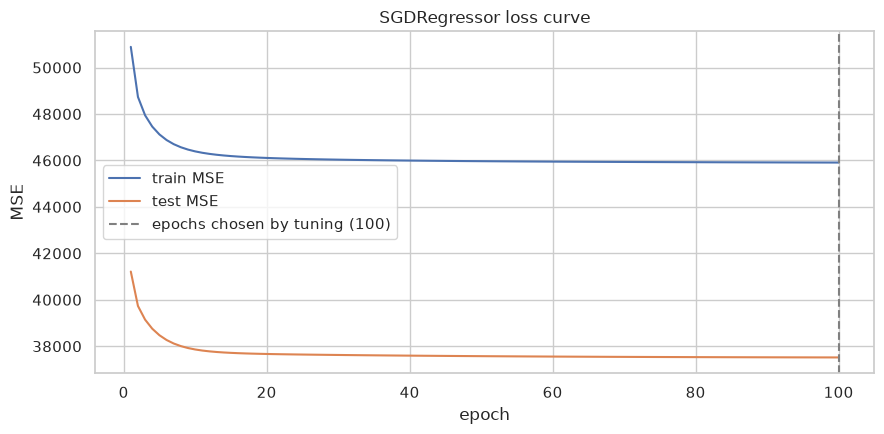

epoch 1: train 50890, test 41215 | epoch 100: train 45908, test 37518


In [ ]:
best_p = {k.replace("model__", ""): v for k, v in sgd_search.best_params_.items()}
EPOCHS = 100
prep_sgd = make_prep().fit(X_train)                       # scaler/encoder fitted on training rows only
A_train, A_test = prep_sgd.transform(X_train), prep_sgd.transform(X_test)

sgd_curve = SGDRegressor(learning_rate="constant", penalty="l2", eta0=best_p["eta0"], alpha=best_p["alpha"],
                         random_state=RANDOM_STATE)
train_loss, test_loss = [], []
for epoch in range(EPOCHS):
    sgd_curve.partial_fit(A_train, y_train)               # one pass over the training data
    train_loss.append(mean_squared_error(y_train, sgd_curve.predict(A_train)))
    test_loss.append(mean_squared_error(y_test, sgd_curve.predict(A_test)))

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, EPOCHS + 1), train_loss, label="train MSE")
plt.plot(range(1, EPOCHS + 1), test_loss, label="test MSE")
plt.axvline(best_p["max_iter"], color="grey", linestyle="--", label="epochs chosen by tuning (%d)" % best_p["max_iter"])
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("SGDRegressor loss curve")
plt.legend(); plt.tight_layout(); plt.show()
print("epoch 1: train %.0f, test %.0f | epoch %d: train %.0f, test %.0f" % (train_loss[0], test_loss[0], EPOCHS, train_loss[-1], test_loss[-1]))

**Answer:** Both curves fall quickly in the first 10 epochs (train from 50,890 to about 46,400, test from 41,215 to about 37,800) and then flatten out, finishing at 45,908 (train) and 37,518 (test) at epoch 100. The curves stay parallel and the test curve never turns upward, so there is no overfitting. The flat, high loss instead points to mild under-fitting: the model is too simple or has too few informative features, so more epochs would not help. The constant gap between the two curves is because the test set happens to be easier (see 6.5), not because of overfitting.

### 7.2 Scatter before and after: the numeric feature most correlated with the target

Correlation of numeric features with the target:
age             0.208
arrival_hour    0.009
dtype: float64
Most correlated feature: age


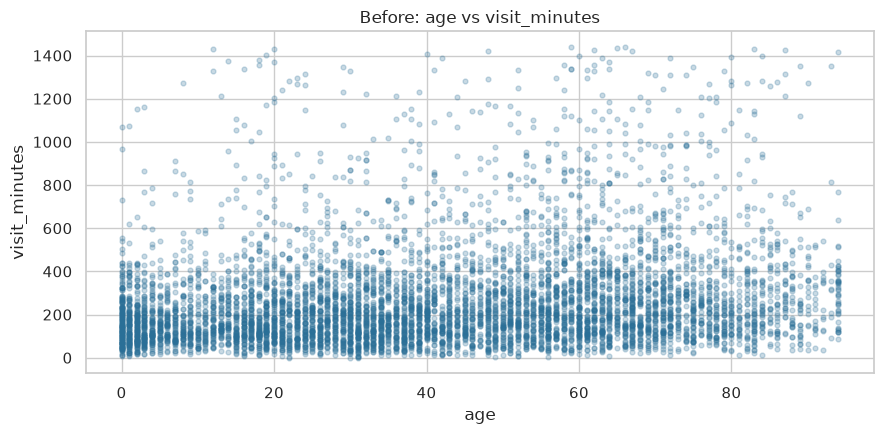

In [ ]:
corr = X_train[FEATURES_NUM].corrwith(y_train)
top = corr.abs().idxmax()
print("Correlation of numeric features with the target:")
print(corr.round(3))
print("Most correlated feature:", top)

plt.figure(figsize=(9, 4.5))
plt.scatter(X_train[top], y_train, alpha=0.25, s=12, color="#2a6f97")
plt.xlabel(top); plt.ylabel(TARGET); plt.title("Before: %s vs %s" % (top, TARGET))
plt.tight_layout(); plt.show()

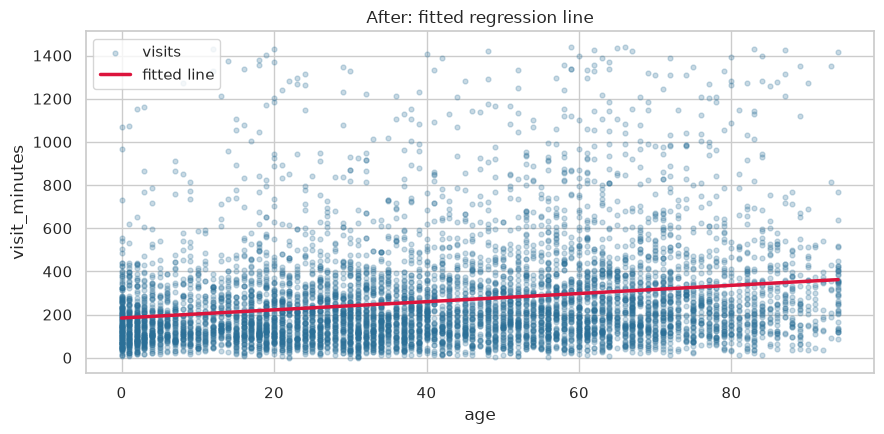

slope: 1.89 minutes per unit of age, intercept: 184.1


In [ ]:
one = LinearRegression().fit(X_train[[top]], y_train)       # one-feature model, for this plot only
xs = np.linspace(X_train[top].min(), X_train[top].max(), 100)
plt.figure(figsize=(9, 4.5))
plt.scatter(X_train[top], y_train, alpha=0.25, s=12, color="#2a6f97", label="visits")
plt.plot(xs, one.predict(pd.DataFrame({top: xs})), color="crimson", linewidth=2.5, label="fitted line")
plt.xlabel(top); plt.ylabel(TARGET); plt.title("After: fitted regression line")
plt.legend(); plt.tight_layout(); plt.show()
print("slope: %.2f minutes per unit of %s, intercept: %.1f" % (one.coef_[0], top, one.intercept_))

**Answer:** Age is the numeric feature most correlated with visit length (0.21; arrival hour is only 0.01). The fitted line slopes upward at about 1.89 minutes per year of age, from about 184 minutes at age 0, so an 80-year-old is predicted to stay roughly 150 minutes longer than a newborn. But the points are spread very widely around the line, and a correlation of 0.21 means age alone explains only about 4% of the variation (0.21 squared). So age has a real trend, but one feature alone describes the target poorly.

### 7.3 Which features matter most (permutation importance on the test set)

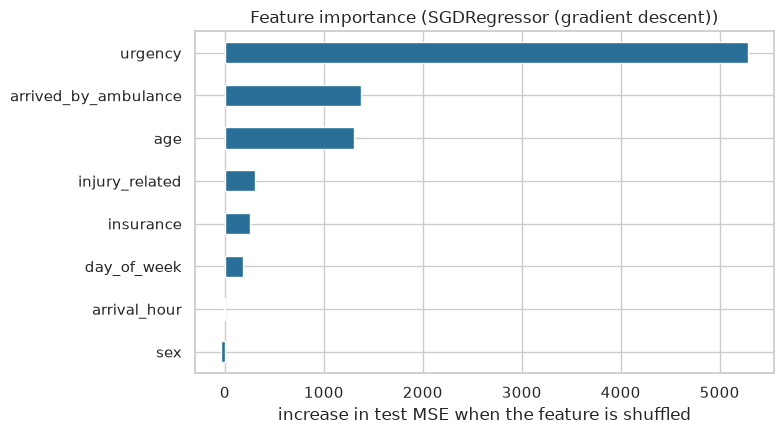

urgency                 5283.6
arrived_by_ambulance    1375.3
age                     1304.1
injury_related           300.4
insurance                252.2
day_of_week              186.2
arrival_hour              -8.7
sex                      -36.4
dtype: float64


In [ ]:
best_model = models[best_name]
imp = permutation_importance(best_model, X_test, y_test, scoring="neg_mean_squared_error",
                             n_repeats=20, random_state=RANDOM_STATE)
imp_df = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(8, 4.5))
imp_df.plot.barh(color="#2a6f97")
plt.xlabel("increase in test MSE when the feature is shuffled"); plt.title("Feature importance (%s)" % best_name)
plt.tight_layout(); plt.show()
print(imp_df.sort_values(ascending=False).round(1))

**Answer:** Urgency matters by far the most (test MSE goes up by about 5,284 when it is shuffled), followed by arriving by ambulance (about 1,375) and age (about 1,304). Injury related (300), insurance (252) and day of week (186) matter a little. Arrival hour (-9) and sex (-36) are about zero or slightly negative, meaning shuffling them did not hurt, so the model is not using them for anything real. This matches what I expected from the box plot and heatmap: sicker patients and ambulance arrivals take longer, and older patients take longer, while the time of arrival and sex don't matter much.

## 8. Save the best model and predict one row

The whole pipeline (encoding + scaling + model) is saved with joblib, so the API only has to call `.predict()`.
The training rows are saved next to it for `/retrain`, which needs the original data to refit non-SGD models.

In [ ]:
joblib.dump(best_model, MODEL_PATH)
train_out = X_train.copy(); train_out[TARGET] = y_train
train_out.to_csv(TRAIN_DATA_PATH, index=False)
print("Saved best model:", best_name, "->", MODEL_PATH)
print("Saved training rows:", train_out.shape, "->", TRAIN_DATA_PATH)

Saved best model: SGDRegressor (gradient descent) -> ../API/best_model.pkl
Saved training rows: (6790, 9) -> ../API/training_data.csv


In [ ]:
def predict_one_test_row(index=0, model_path=MODEL_PATH):
    """Load the saved pipeline and predict the target for one row of the test set."""
    model = joblib.load(model_path)
    row = X_test.iloc[[index]]
    predicted = float(model.predict(row)[0])
    actual = float(y_test.iloc[index])
    print("Inputs:", row.iloc[0].to_dict())
    print("Predicted visit: %.0f minutes | Actual visit: %.0f minutes" % (predicted, actual))
    return predicted

predict_one_test_row(0)
print()
predict_one_test_row(1)

Inputs: {'age': 46, 'arrival_hour': 8, 'sex': 'Female', 'day_of_week': 'Tuesday', 'arrived_by_ambulance': 'No', 'urgency': 'Urgent', 'injury_related': 'No', 'insurance': 'Private'}
Predicted visit: 279 minutes | Actual visit: 179 minutes

Inputs: {'age': 2, 'arrival_hour': 20, 'sex': 'Female', 'day_of_week': 'Monday', 'arrived_by_ambulance': 'No', 'urgency': 'Urgent', 'injury_related': 'No', 'insurance': 'Medicaid'}
Predicted visit: 255 minutes | Actual visit: 454 minutes


255.14218435414523

**Answer:** For the first test row (46-year-old, urgent, arrived by car) the model predicted 279 minutes and the actual visit was 179, so it was 100 minutes too high. For the second (a 2-year-old, urgent) it predicted 255 and the actual was 454, so it was about 199 minutes too low. Both misses are about the size of the model's typical error (RMSE about 194 minutes). One row says very little about quality, because any single visit can be unusually short or long for reasons the inputs don't capture, and the two errors go in opposite directions. The right measure is the test MSE over all 1,698 test rows (37,563), which compared with the 42,598 baseline shows the model is only modestly better than guessing the average.